In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

DATA_PATH = "../dataset/orders_sample.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2018, 17)


,order_id,order_datetime,customer_name,phone,address,city,state,pincode,order_value,items,num_items,customer_prior_orders,customer_prior_rto,utm_source,courier,payment_method,final_status
0,KT100193,2026-06-18 15:34,Lakshmi Shaikh,6007018646,"Station chowk se left, Hanuman Mandir ke saamne",Chennai,Tamil Nadu,600084.0,349,Satin Pillowcase,1,0,0,meta_ads,Delhivery,COD,DELIVERED
1,KT101714,2026-07-26 09:36,Tanvi Das,9895118261,"Link chowk se left, SBI Bank ke saamne",Indore,Madhya Pradesh,452026.0,898,Rice Water Shampoo Bar|Satin Bonnet,2,0,0,meta_ads,BlueDart,COD,DELIVERED
2,KT100452,2026-05-29 22:37,Swati Das,9583831354,"399/13, Station Nagar, Opp. Railway Crossing",Chennai,Tamil Nadu,600092.0,449,Satin Pillowcase,1,0,0,meta_ads,Delhivery,COD,DELIVERED
3,KT101753,2026-06-29 12:46,Meera Pillai,9109605378,"784/17, MG Nagar, Opp. Hanuman Mandir",Lucknow,Uttar Pradesh,226036.0,699,Satin Bonnet,1,0,0,direct,Xpressbees,COD,RTO
4,KT100195,2026-05-13 14:15,Sneha Reddy,6763180097,"ph krke aana, Govt School ke paas",Hyderabad,Telangana,500058.0,499,Claw Clip Set,1,0,0,meta_ads,Xpressbees,COD,DELIVERED


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2018 entries, 0 to 2017
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               2018 non-null   str    
 1   order_datetime         2018 non-null   str    
 2   customer_name          2018 non-null   str    
 3   phone                  2018 non-null   str    
 4   address                2018 non-null   str    
 5   city                   2014 non-null   str    
 6   state                  2018 non-null   str    
 7   pincode                2006 non-null   float64
 8   order_value            2018 non-null   int64  
 9   items                  2018 non-null   str    
 10  num_items              2018 non-null   int64  
 11  customer_prior_orders  2018 non-null   int64  
 12  customer_prior_rto     2018 non-null   int64  
 13  utm_source             2018 non-null   str    
 14  courier                2018 non-null   str    
 15  payment_method 

In [4]:
df.describe(include='all')

,order_id,order_datetime,customer_name,phone,address,city,state,pincode,order_value,items,num_items,customer_prior_orders,customer_prior_rto,utm_source,courier,payment_method,final_status
count,2018,2018,2018,2018,2018,2014,2018,2006.000000,2018.000000,2018,2018.000000,2018.000000,2018.000000,2018,2018,2018,2018
unique,1988,1976,549,1490,1516,19,11,NaN,NaN,369,NaN,NaN,NaN,6,5,1,6
top,KT100329,2026-04-17 14:10,Priya Iyer,9805943782,.,Delhi,Maharashtra,NaN,NaN,Claw Clip Set,NaN,NaN,NaN,meta_ads,Delhivery,COD,DELIVERED
freq,2,2,13,5,41,246,390,NaN,NaN,136,NaN,NaN,NaN,780,707,2018,1443
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,449327.535394,918.710109,NaN,1.796829,0.736373,0.088702,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202881.411647,577.176932,NaN,0.894732,1.466491,0.338507,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,110001.000000,0.000000,NaN,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,302047.250000,449.000000,NaN,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,452015.000000,748.000000,NaN,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,560092.000000,1198.000000,NaN,2.000000,0.000000,0.000000,NaN,NaN,NaN,NaN


In [5]:
df['final_status'].value_counts()

final_status
DELIVERED     1443
RTO            570
Rto              2
delivered        1
RTO              1
IN_TRANSIT       1
Name: count, dtype: int64

In [6]:
df['final_status'].value_counts()

final_status
DELIVERED     1443
RTO            570
Rto              2
delivered        1
RTO              1
IN_TRANSIT       1
Name: count, dtype: int64

In [7]:
analysis_df = df[
    df['final_status'].isin(['DELIVERED', 'RTO'])
].copy()

In [8]:
total_orders = len(analysis_df)

rto_orders = (
    analysis_df['final_status'] == 'RTO'
).sum()

delivered_orders = (
    analysis_df['final_status'] == 'DELIVERED'
).sum()

rto_rate = (rto_orders / total_orders) * 100

print("Total completed orders:", total_orders)
print("Delivered orders:", delivered_orders)
print("RTO orders:", rto_orders)
print("RTO Rate:", round(rto_rate, 2), "%")

Total completed orders: 2013
Delivered orders: 1443
RTO orders: 570
RTO Rate: 28.32 %


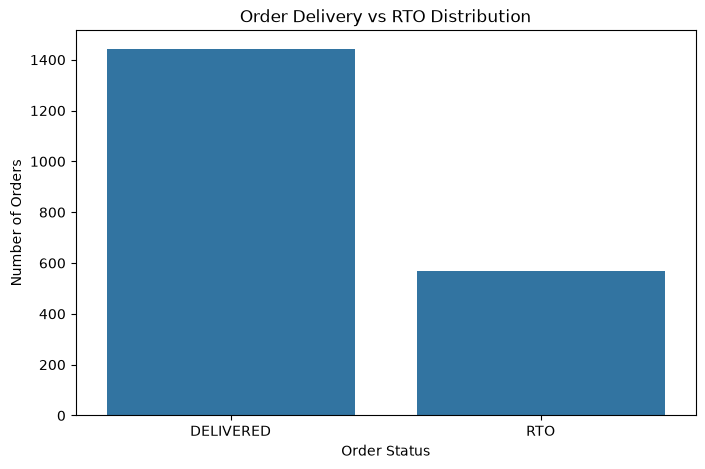

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=analysis_df,
    x='final_status'
)

plt.title('Order Delivery vs RTO Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')

plt.show()

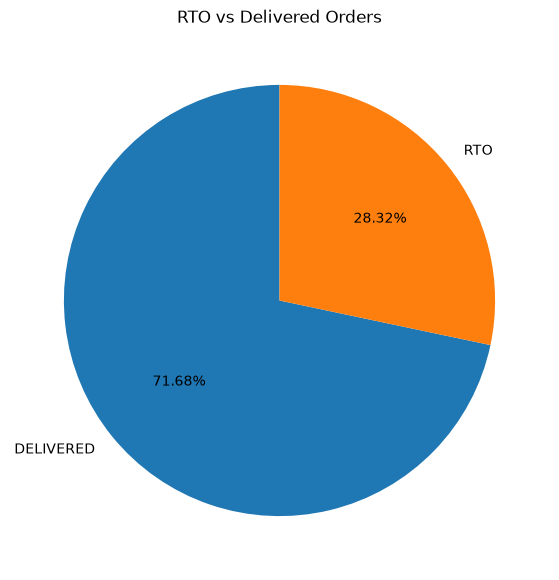

In [10]:
status_counts = analysis_df['final_status'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.2f%%',
    startangle=90
)

plt.title('RTO vs Delivered Orders')

plt.show()

In [11]:
missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
]

print(missing_values)

city        4
pincode    12
dtype: int64


In [12]:
duplicate_count = df['order_id'].duplicated().sum()

print("Duplicate order IDs:", duplicate_count)

Duplicate order IDs: 30


In [13]:
suspicious_addresses = df[
    df['address'].astype(str).str.strip().eq('.')
]

print("Suspicious address records:", len(suspicious_addresses))

suspicious_addresses[
    ['order_id', 'customer_name', 'address', 'city', 'pincode']
].head(10)

Suspicious address records: 41


,order_id,customer_name,address,city,pincode
147,KT100148,Ananya Shaikh,.,Chennai,600038.0
160,KT100670,Pooja Verma,.,Mumbai,400084.0
196,KT101511,Kavya Bose,.,Hyderabad,500051.0
240,KT100187,Sneha Iyer,.,Bengaluru,560006.0
254,KT101124,Kavya Khan,.,Delhi,110030.0
255,KT100721,Megha Kulkarni,.,Mumbai,400013.0
485,KT100694,Test Order,.,Kolkata,700038.0
504,KT100663,Deepika Sharma,.,Kolkata,700041.0
590,KT100334,Deepika Joshi,.,Delhi,110014.0
713,KT101130,Sana Singh,.,Sagar,470065.0


In [14]:
numerical_columns = [
    'order_value',
    'num_items',
    'customer_prior_orders',
    'customer_prior_rto'
]

print(
    analysis_df[numerical_columns].describe()
)

       order_value    num_items  customer_prior_orders  customer_prior_rto
count  2013.000000  2013.000000            2013.000000         2013.000000
mean    918.165922     1.795827               0.737208            0.088425
std     577.184246     0.894840               1.467674            0.338295
min       0.000000     1.000000               0.000000            0.000000
25%     449.000000     1.000000               0.000000            0.000000
50%     748.000000     2.000000               0.000000            0.000000
75%    1198.000000     2.000000               0.000000            0.000000
max    2999.000000     4.000000               5.000000            2.000000


In [15]:
customer_analysis = (
    analysis_df
    .groupby('customer_prior_orders')
    .agg(
        total_orders=('order_id', 'count'),
        rto_orders=(
            'final_status',
            lambda x: (x == 'RTO').sum()
        )
    )
)

customer_analysis['rto_rate'] = (
    customer_analysis['rto_orders'] /
    customer_analysis['total_orders'] * 100
)

print(customer_analysis)

                       total_orders  rto_orders   rto_rate
customer_prior_orders                                     
0                              1514         458  30.250991
1                               104          16  15.384615
2                               101          18  17.821782
3                                99          25  25.252525
4                                94          22  23.404255
5                               101          31  30.693069


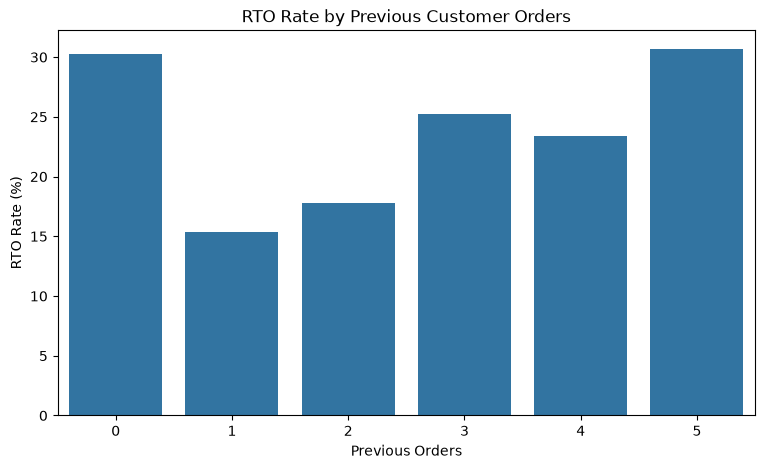

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=customer_analysis.index,
    y=customer_analysis['rto_rate']
)

plt.title('RTO Rate by Previous Customer Orders')
plt.xlabel('Previous Orders')
plt.ylabel('RTO Rate (%)')

plt.show()

In [17]:
courier_analysis = (
    analysis_df
    .groupby('courier')
    .agg(
        total_orders=('order_id', 'count'),
        rto_orders=(
            'final_status',
            lambda x: (x == 'RTO').sum()
        )
    )
)

courier_analysis['rto_rate'] = (
    courier_analysis['rto_orders'] /
    courier_analysis['total_orders'] * 100
)

print(courier_analysis.sort_values(
    by='rto_rate',
    ascending=False
))

              total_orders  rto_orders   rto_rate
courier                                          
Xpressbees             396         124  31.313131
Ecom Express           305          92  30.163934
BlueDart               187          54  28.877005
Shadowfax              421         119  28.266033
Delhivery              704         181  25.710227


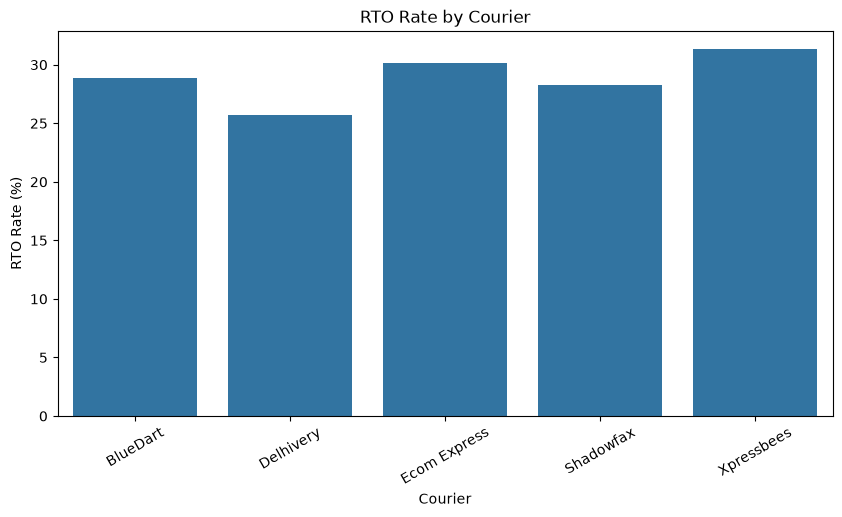

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=courier_analysis.reset_index(),
    x='courier',
    y='rto_rate'
)

plt.title('RTO Rate by Courier')
plt.xlabel('Courier')
plt.ylabel('RTO Rate (%)')

plt.xticks(rotation=30)

plt.show()

In [19]:
source_analysis = (
    analysis_df
    .groupby('utm_source')
    .agg(
        total_orders=('order_id', 'count'),
        rto_orders=(
            'final_status',
            lambda x: (x == 'RTO').sum()
        )
    )
)

source_analysis['rto_rate'] = (
    source_analysis['rto_orders'] /
    source_analysis['total_orders'] * 100
)

print(source_analysis.sort_values(
    by='rto_rate',
    ascending=False
))

                    total_orders  rto_orders   rto_rate
utm_source                                             
meta_ads                     777         243  31.274131
instagram_organic            234          68  29.059829
google_ads                   246          69  28.048780
influencer                   229          61  26.637555
whatsapp_broadcast           271          71  26.199262
direct                       256          58  22.656250
